# Look at one hole

**Point this at a downloaded `.zip` and it shows you the data.** Tables, columns, what's in
each one. That's all it does.

**To use it:** put this notebook in the same folder as a HyLogger `.zip`, then `Cell > Run All`.
It finds the zip, unpacks what it needs, and shows you the tables. Works on Windows, Mac and
Linux. The first two cells check your libraries and locate your data, and tell you exactly
what to do if either is missing.

You get three tables:

| Table | What it is | Size |
|-------|-----------|------|
| `where` | Where each reading sits — tray, depth | ~26,000 rows × 7 |
| `scalars` | Everything the scanner software worked out, incl. minerals | ~26,000 rows × 151 |
| `spectra_nir` / `spectra_tir` | The raw light measurements | ~26,000 rows × 531 and × 341 |

Plus `columns` — a plain-English list of every column, how full it is, and typical values.
That's the one to skim before the meeting.

### First: do you have the libraries?

Run this. If anything is missing it prints the exact command to fix it.

In [1]:
import importlib.util
import sys

needed = {"pytsg": "pytsg", "pandas": "pandas", "numpy": "numpy",
          "matplotlib": "matplotlib"}
missing = [pip_name for module, pip_name in needed.items()
           if importlib.util.find_spec(module) is None]

print(f"Python {sys.version.split()[0]}")
if missing:
    print("\nMISSING: " + ", ".join(missing))
    print("\nRun this in a terminal, then restart the kernel:\n")
    print(f"    pip install {' '.join(missing)}\n")
    print("Or run it right here by putting this in a new cell:\n")
    print(f"    %pip install {' '.join(missing)}")
else:
    print("All libraries present. Carry on.")

Python 3.14.3
All libraries present. Carry on.


### Second: where is your data?

Set `SOURCE` below to your downloaded `.zip` (or to the folder if you already unzipped).

**Leave it as `None` and it will look for a zip by itself** — in this notebook's folder, then
the folder above it. So if you drop this notebook next to the zip, it just works.

Don't have data yet? Grab a hole from
<https://thredds.nci.org.au/thredds/catalog/rs07/WA/catalog.html> — any `.zip` in that list.

In [2]:
# ============================================================
#  THE ONLY LINE YOU NEED TO CHANGE
#  None = find a zip automatically. Or put a path here:
#     SOURCE = "05GJD001.zip"
#     SOURCE = "/Users/me/Downloads/KD1.zip"       (Mac / Linux)
#     SOURCE = r"C:\Users\me\Downloads\KD1.zip"    (Windows)
# ============================================================
SOURCE = "../data/05GJD001.zip"  # or None to find a zip automatically

# Extracting everything takes ~900 MB and includes core photos you don't need for a data look.
# False = skip the photos and the big linescan image, extract only what holds the numbers.
EXTRACT_EVERYTHING = False
# ============================================================

import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pytsg import parse_tsg

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

HERE = Path.cwd()

def is_hylogger_zip(path):
    """True if this zip actually holds HyLogger data (not just any zip lying around)."""
    try:
        with zipfile.ZipFile(path) as archive:
            return any(n.endswith("_tsg.tsg") for n in archive.namelist())
    except (zipfile.BadZipFile, OSError):
        return False


if SOURCE is None:
    # Look for an already-extracted package first, then a zip, near the notebook.
    candidates = []
    for folder in (HERE, HERE.parent):
        candidates += [p.parent for p in folder.rglob("*_tsg.tsg")]
        candidates += [z for z in sorted(folder.glob("*.zip")) if is_hylogger_zip(z)]

    if not candidates:
        raise FileNotFoundError(
            f"No .zip or HyLogger folder found in {HERE} or {HERE.parent}.\n"
            "Set SOURCE to the path of your downloaded zip and run this cell again."
        )
    SOURCE = candidates[0]
    print(f"Found {len(candidates)} candidate(s); using the first.")

SOURCE = Path(SOURCE).expanduser().resolve()
print("Source:", SOURCE)

if not SOURCE.exists():
    raise FileNotFoundError(
        f"{SOURCE} does not exist.\n"
        "Check the path — on Windows use r\"C:\\path\\to\\file.zip\" (note the r)."
    )

Source: C:\Users\DCCN9\OneDrive - UWA\Data Science\4-Semester July-November 2026\Clapstone\data\05GJD001.zip


In [3]:
# Unzip if needed. If the folder is already there, this skips straight past.
if SOURCE.suffix.lower() == ".zip":
    target = SOURCE.with_suffix("")  # 05GJD001.zip -> 05GJD001/

    if target.exists():
        print(f"Already extracted -> {target}")
    else:
        with zipfile.ZipFile(SOURCE) as archive:
            wanted = archive.namelist()
            if not EXTRACT_EVERYTHING:
                wanted = [
                    n for n in wanted
                    if not n.lower().endswith((".jpg", ".jpeg", ".png"))
                    and "_cras" not in n.lower()
                ]
            size_mb = sum(i.file_size for i in archive.infolist() if i.filename in wanted) / 1e6
            print(f"Extracting {len(wanted)} files ({size_mb:.0f} MB) -> {target}")
            archive.extractall(target, members=wanted)
        print("Done.")
    search_root = target
else:
    search_root = SOURCE

# The actual data sits in a subfolder named with a long UUID. Find it by its header file.
header_file = next(search_root.rglob("*_tsg.tsg"), None)
if header_file is None:
    raise FileNotFoundError(f"No HyLogger data found under {search_root}")

PACKAGE = header_file.parent
print("\nHyLogger package:", PACKAGE.name)
print("\nFiles in it:")
for f in sorted(PACKAGE.iterdir()):
    print(f"   {f.name:34s} {f.stat().st_size / 1e6:8.1f} MB")

Already extracted -> C:\Users\DCCN9\OneDrive - UWA\Data Science\4-Semester July-November 2026\Clapstone\data\05GJD001

HyLogger package: 8a294cfc-68df-4f03-995b-c5fd0d47ab0

Files in it:
   05GJD001_tsg.bip                      110.2 MB
   05GJD001_tsg.cal                        0.3 MB
   05GJD001_tsg.ini                        0.1 MB
   05GJD001_tsg.tsg                        2.0 MB
   05GJD001_tsg_1.ini                      0.1 MB
   05GJD001_tsg_2.ini                      0.1 MB
   05GJD001_tsg_3.ini                      0.1 MB
   05GJD001_tsg_hires.dat                 13.3 MB
   05GJD001_tsg_tir.bip                   70.8 MB
   05GJD001_tsg_tir.cal                    0.8 MB
   05GJD001_tsg_tir.ini                    0.1 MB
   05GJD001_tsg_tir.tsg                    2.1 MB


In [4]:
# Load it. Takes 20-40 seconds — it's reading a few hundred MB of binary.
package = parse_tsg.read_package(PACKAGE, read_cras_file=False)

nir = package.nir  # visible + near-infrared scan
tir = package.tir  # thermal infrared scan

hole_id = str(nir.sampleheaders["H"].iloc[0])

print(f"Hole            : {hole_id}")
print(f"Readings        : {len(nir.sampleheaders):,}")
print(f"NIR spectra     : {nir.spectra.shape[0]:,} readings x {nir.spectra.shape[1]} wavelengths "
      f"({nir.wavelength.min():.0f}-{nir.wavelength.max():.0f} nm)")
print(f"TIR spectra     : {tir.spectra.shape[0]:,} readings x {tir.spectra.shape[1]} wavelengths "
      f"({tir.wavelength.min():.0f}-{tir.wavelength.max():.0f} nm)")
print(f"Scalar columns  : {nir.scalars.shape[1]}")

Hole            : 05GJD001
Readings        : 25,938
NIR spectra     : 25,938 readings x 531 wavelengths (380-2500 nm)
TIR spectra     : 25,938 readings x 341 wavelengths (6000-14500 nm)
Scalar columns  : 151


## Table 1 — where each reading is

One row per reading. `D` is **depth in metres**, which is the column that matters.
`T` = tray, `L` = row within the tray, `P` = position along that row, `X` = mm along the scan.

In [5]:
where = nir.sampleheaders.copy()
where["D"] = pd.to_numeric(where["D"], errors="coerce")
where["X"] = pd.to_numeric(where["X"], errors="coerce")
where = where.rename(columns={"T": "tray", "L": "line", "P": "position",
                              "D": "depth_m", "X": "dist_mm", "H": "hole_id"})

print(f"{len(where):,} readings, from {where['depth_m'].min():.1f} m "
      f"to {where['depth_m'].max():.1f} m deep, across {where['tray'].nunique()} trays")
display(where.head(10))

25,938 readings, from 150.0 m to 316.0 m deep, across 33 trays


,sample,tray,line,position,depth_m,dist_mm,hole_id
0,0,0001,1,1,150.000008,6.263977,05GJD001
1,1,0001,1,2,150.000005,14.263977,05GJD001
2,2,0001,1,3,150.000002,22.263977,05GJD001
3,3,0001,1,4,150.000009,30.263977,05GJD001
4,4,0001,1,5,150.000006,38.263977,05GJD001
5,5,0001,1,6,150.000003,46.263977,05GJD001
6,6,0001,1,7,150.000000,54.263977,05GJD001
7,7,0001,1,8,150.000007,62.263977,05GJD001
8,8,0001,1,9,150.000004,70.263977,05GJD001
9,9,0001,1,10,150.000001,78.263977,05GJD001


## Table 2 — the scalars

Everything the TSG software calculated. 151 columns. **This is where the mineral names live.**

One critical thing: TSG writes "no value" as `-3.402823e+38` instead of leaving it blank.
The next cell converts those to proper empty cells — otherwise every average you compute
comes out as a huge negative number.

In [6]:
scalars = nir.scalars.copy()

for col in scalars.columns:
    if pd.api.types.is_numeric_dtype(scalars[col]):
        scalars[col] = scalars[col].where(scalars[col] > -1e38)   # the sentinel
    else:
        scalars[col] = scalars[col].replace("", np.nan)           # blank text

display(scalars.head(10))

,Flags,FeatExMethod,NumFeats,Depth1,Centre1,Width1,Depth2,Centre2,Width2,Depth3,Centre3,Width3,Depth4,Centre4,Width4,Depth5,Centre5,Width5,Depth6,Centre6,...,CustScore,Ferric oxide abundance 25062014,Min3 sTSAS,prof_min,Min1 sTSAS,w2200,Tray,TNorm uTSAS,Wt3 sTSAS,Grp3 uTSAS,SecSamp,Wt2 uTSAS,Min2 sTSAS,Min2 sTSAV,Wt1 sTSAS,Grp3 sTSAS,virtual_section,Wt2 sTSAS,Error uTSAS,TraySamp
0,0.291667,0.0,25.0,0.214664,2464.000244,44.002773,0.047224,2428.000244,16.001074,0.208215,2400.000000,52.003189,0.041005,2376.000244,16.001074,0.113770,2360.000244,20.001522,0.469602,2316.000244,...,NaN,NaN,NaN,57.494873,NaN,NaN,0001,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0
1,1.218750,0.0,25.0,0.196226,2464.000244,44.002773,0.043670,2428.000244,16.001074,0.172275,2400.000000,52.003189,0.026766,2376.000244,16.001074,0.079573,2360.000244,20.001522,0.429740,2316.000244,...,NaN,NaN,NaN,33.007324,NaN,NaN,0001,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,2.0
2,2.013258,0.0,25.0,0.028881,2480.000000,36.002357,0.010935,2460.000000,24.001490,0.009019,2368.000000,36.002357,0.045659,2336.000244,52.003189,0.071015,2276.000000,60.004086,0.008725,2164.000000,...,NaN,NaN,NaN,19.180742,NaN,NaN,0001,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,3.0
3,3.087500,0.0,25.0,0.032262,2480.000000,36.002357,0.009815,2456.000000,24.001728,0.009399,2372.000244,28.001699,0.046680,2336.000244,52.003189,0.068251,2276.000000,52.003429,0.013004,2168.000244,...,NaN,NaN,NaN,38.273216,NaN,NaN,0001,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,4.0
4,4.388889,0.0,25.0,0.033482,2480.000000,36.002357,0.009707,2456.000000,24.001728,0.009956,2372.000244,28.001699,0.050523,2336.000244,52.003189,0.077490,2272.000000,60.003845,0.012702,2164.000000,...,NaN,NaN,NaN,38.916069,NaN,NaN,0001,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,5.0
5,5.291667,0.0,25.0,0.035914,2480.000000,36.002357,0.009614,2460.000000,20.001284,0.009700,2376.000244,32.002148,0.053891,2336.000244,56.003639,0.090564,2276.000000,64.004295,0.016073,2164.000000,...,NaN,NaN,NaN,39.355274,NaN,NaN,0001,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,6.0
6,6.025735,0.0,25.0,0.036810,2480.000000,36.002357,0.009492,2456.000000,16.001074,0.010395,2380.000000,28.001938,0.057492,2336.000244,56.003639,0.093450,2276.000000,64.004295,0.016858,2160.000000,...,NaN,NaN,NaN,39.596909,NaN,NaN,0001,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,7.0
7,7.145833,0.0,25.0,0.038820,2480.000000,36.002357,0.012530,2456.000000,20.001522,0.011076,2376.000244,32.002148,0.058539,2336.000244,52.003189,0.096687,2272.000000,68.004501,0.027619,2156.000244,...,NaN,NaN,NaN,40.092346,NaN,NaN,0001,NaN,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,8.0
8,8.350000,0.0,25.0,0.032537,2476.000000,32.002148,0.009884,2456.000000,20.001522,0.008998,2376.000244,28.001938,0.056234,2336.000244,56.003639,0.095403,2276.000000,64.004295,0.022242,2160.000000,...,NaN,NaN,NaN,36.584789,NaN,NaN,0001,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,9.0
9,9.218750,0.0,24.0,0.017307,2480.000000,40.002567,0.051503,2344.000000,72.004715,0.038520,2264.000244,32.002148,0.022517,2196.000000,28.001938,0.030844,2100.000244,80.005135,0.009309,2044.000122,...,NaN,NaN,NaN,0.781270,NaN,NaN,0001,NaN,NaN,NaN,10.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,10.0


## The column list — what to skim before the meeting

Every column, how full it is, and what's actually in it. Sorted so the emptiest are at the top,
because "which columns are half missing" is the first thing worth knowing.

In [7]:
rows = []
for col in scalars.columns:
    s = scalars[col]
    filled = s.notna().mean() * 100

    if pd.api.types.is_numeric_dtype(s) and s.notna().any():
        kind = "number"
        example = f"{s.min():.3g} to {s.max():.3g}   (median {s.median():.3g})"
    elif s.notna().any():
        kind = "text"
        top = s.value_counts().head(3)
        example = ", ".join(f"{v} ({n:,})" for v, n in top.items())
    else:
        kind = "empty"
        example = "-- no values at all --"

    rows.append({"column": col, "type": kind, "filled_%": round(filled, 1),
                 "distinct": s.nunique(), "what's in it": example})

columns = pd.DataFrame(rows).sort_values("filled_%").reset_index(drop=True)

print(f"{len(columns)} columns. "
      f"{(columns['filled_%'] == 100).sum()} are completely full, "
      f"{(columns['filled_%'] < 100).sum()} have gaps, "
      f"{(columns['filled_%'] == 0).sum()} are entirely empty.\n")

with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(columns)

151 columns. 98 are completely full, 53 have gaps, 4 are entirely empty.



,column,type,filled_%,distinct,what's in it
0,CustSample,empty,0.0,0,-- no values at all --
1,RockMarks,empty,0.0,0,-- no values at all --
2,CustGroup,empty,0.0,0,-- no values at all --
3,CustScore,empty,0.0,0,-- no values at all --
4,Grp2 sTSAV,text,0.7,1,OXIDE (177)
5,Wt2 sTSAV,number,0.7,177,0.201 to 0.5 (median 0.311)
6,Min2 sTSAV,number,0.7,2,4 to 5 (median 4)
7,Interactive Depth Logging,number,3.1,106,-1.68e+07 to 1.68e+07 (median 170)
8,Min3 uTSAS,text,13.8,24,"Muscovite (580), Prehnite (484), Siderite (437)"
9,Grp3 uTSAS,text,13.8,10,"WHITE-MICA (889), CARBONATE (862), OTHER-ALOH (484)"


In [8]:
def find(text):
    """Search the columns. Try find('Min'), find('water'), find('error')."""
    hits = columns[columns["column"].str.contains(text, case=False, na=False)]
    with pd.option_context("display.max_colwidth", 70):
        display(hits)


# The mineral columns are the interesting ones:
find("Min")

,column,type,filled_%,distinct,what's in it
6,Min2 sTSAV,number,0.7,2,4 to 5 (median 4)
8,Min3 uTSAS,text,13.8,24,"Muscovite (580), Prehnite (484), Siderite (437)"
12,Min3 sTSAS,text,14.8,39,"Muscovite (570), Prehnite (461), Gypsum (391)"
16,Min1 sTSAV,number,36.5,5,4 to 15 (median 4)
22,Min2 uTSAS,text,48.3,27,"Muscovite (3,501), Siderite (1,261), Phlogopite (1,197)"
23,Min2 sTSAS,text,51.2,48,"Muscovite (3,483), Siderite (1,229), Phlogopite (1,152)"
36,Min1 uTSAS,text,61.7,26,"Chlorite-FeMg (5,374), Siderite (1,925), Aspectral (1,754)"
37,Min1 sTSAS,text,63.3,39,"Chlorite-FeMg (5,482), Siderite (1,955), Biotite (1,472)"
147,prof_min,number,100.0,12857,0 to 66.9 (median 21.9)


**Decoding those names**, because they are not obvious:

- `Min1`, `Min2`, `Min3` — the 1st, 2nd and 3rd most abundant mineral at that reading
- `Wt1`, `Wt2`, `Wt3` — how much of each one (0 to 1)
- `Grp1`, `Grp2`, `Grp3` — the mineral *family* (CHLORITE, WHITE-MICA, CARBONATE...)
- `Error` — how bad the match was. High error means don't trust the name
- The suffix is which reference library was used: `sTSAS` = system/SWIR,
  `uTSAS` = user/SWIR, `sTSAV` = system/visible

**`Min1 sTSAS` is a software guess, not a verified fact.** Nobody has checked it against
the actual rock. Good question for the client: how much do they trust it?

One oddity you'll spot in the list above: the `sTSAV` mineral columns come back as *numbers*
(4, 5) rather than names, while the `sTSAS` ones are text. Those numbers are codes into a
lookup table that ships inside the file — `package.nir.classes` holds it. Not a problem,
just something to remember before you try to read them as mineral names.

## Table 3 — the spectra

The raw measurement: how much light bounced back at each wavelength. Columns are wavelengths
in nanometres, rows are readings. This is the part the machine learning would actually run on.

In [9]:
spectra_nir = pd.DataFrame(nir.spectra, columns=[f"{w:.0f}nm" for w in nir.wavelength])
spectra_tir = pd.DataFrame(tir.spectra, columns=[f"{w:.0f}nm" for w in tir.wavelength])

spectra_nir.insert(0, "depth_m", where["depth_m"].values)
spectra_tir.insert(0, "depth_m", where["depth_m"].values)

print(f"NIR: {spectra_nir.shape[0]:,} rows x {spectra_nir.shape[1] - 1} wavelengths")
display(spectra_nir.iloc[:8, :10])

NIR: 25,938 rows x 531 wavelengths


,depth_m,380nm,384nm,388nm,392nm,396nm,400nm,404nm,408nm,412nm
0,150.000008,0.274457,0.272749,0.271406,0.271701,0.272189,0.273984,0.276286,0.279866,0.285116
1,150.000005,0.171825,0.170816,0.169688,0.169642,0.169748,0.170297,0.171257,0.172912,0.175482
2,150.000002,0.065050,0.064883,0.064641,0.064530,0.064270,0.064188,0.064106,0.064113,0.064216
3,150.000009,0.113496,0.111963,0.110172,0.108784,0.107408,0.106245,0.105287,0.104734,0.104957
4,150.000006,0.110763,0.109076,0.107281,0.105940,0.104523,0.103497,0.102641,0.102273,0.102561
5,150.000003,0.100799,0.099516,0.098102,0.096844,0.095419,0.094277,0.093288,0.092749,0.092653
6,150.000000,0.089090,0.087398,0.085490,0.083850,0.082043,0.080447,0.079064,0.078097,0.077779
7,150.000007,0.087753,0.085672,0.083281,0.081195,0.078984,0.077135,0.075640,0.074591,0.074259


## One joined table

The three tables above line up row-for-row, so they join directly. Here are the useful
columns in one place — and saved to CSV so you can open it in Excel.

In [10]:
# Not every hole has every column — it depends on how GSWA processed that scan. So we ask
# for columns by name and fall back to blanks rather than crashing on a hole that lacks one.
def get(column_name):
    if column_name in scalars.columns:
        return scalars[column_name].values
    return np.full(len(scalars), np.nan)


wanted = {
    "mineral_1": "Min1 sTSAS", "weight_1": "Wt1 sTSAS", "group_1": "Grp1 sTSAS",
    "mineral_2": "Min2 sTSAS", "weight_2": "Wt2 sTSAS", "error": "Error sTSAS",
    "albedo": "Albedo", "quality_flag": "HyLogDiag",
}
absent = [name for name in wanted.values() if name not in scalars.columns]
if absent:
    print(f"NOTE: this hole has no {absent} — those columns will be blank below.")
    print("      Check the `columns` table above to see what it does have instead.\n")

data = pd.DataFrame({"hole_id": hole_id,
                     "depth_m": where["depth_m"].values,
                     "tray": where["tray"].values,
                     **{label: get(name) for label, name in wanted.items()}})

mask = get("Final Mask")
data["kept_by_mask"] = mask == 1
data = data.sort_values("depth_m").reset_index(drop=True)

out_file = Path.cwd() / f"{hole_id}_data.csv"
data.to_csv(out_file, index=False)
print(f"Saved -> {out_file}\n")

print("First rows (the very top of the hole is usually masked, so minerals are blank):")
display(data.head(8))

identified = data.dropna(subset=["mineral_1"])
if len(identified):
    print("\nA random sample of rows that DO have a mineral:")
    display(identified.sample(min(12, len(identified)), random_state=0).sort_values("depth_m"))

    print(f"\nReadings with a mineral identified: {len(identified):,} "
          f"of {len(data):,}  ({len(identified) / len(data):.0%})")
    print("The rest were masked out — tray markers, gaps, or a match too poor to report.")
else:
    print("\nNo minerals identified in this hole via 'Min1 sTSAS'.")
    print("Look at the `columns` table above — this hole may use different column names.")

Saved -> c:\Users\DCCN9\OneDrive - UWA\Data Science\4-Semester July-November 2026\Clapstone\data_view\05GJD001_data.csv

First rows (the very top of the hole is usually masked, so minerals are blank):


,hole_id,depth_m,tray,mineral_1,weight_1,group_1,mineral_2,weight_2,error,albedo,quality_flag,kept_by_mask
0,05GJD001,150.000000,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.361269,Good,False
1,05GJD001,150.000001,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.074865,PZ,False
2,05GJD001,150.000002,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.162507,Good,False
3,05GJD001,150.000003,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.343149,Good,False
4,05GJD001,150.000004,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.301618,Good,False
5,05GJD001,150.000005,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.287545,Good,False
6,05GJD001,150.000006,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.326515,Good,False
7,05GJD001,150.000007,0001,NaN,NaN,NaN,NaN,NaN,NaN,0.372578,Good,False



A random sample of rows that DO have a mineral:


,hole_id,depth_m,tray,mineral_1,weight_1,group_1,mineral_2,weight_2,error,albedo,quality_flag,kept_by_mask
6962,05GJD001,194.278915,0009,Chlorite-FeMg,0.652087,CHLORITE,Muscovite,0.347913,147.554565,0.203941,Good,True
8633,05GJD001,204.268294,0011,Chlorite-FeMg,0.513039,CHLORITE,Biotite,0.310183,134.814301,0.168993,Good,True
9768,05GJD001,211.857685,0013,Chlorite-FeMg,0.735098,CHLORITE,Muscovite,0.264902,127.762215,0.270443,Good,True
10509,05GJD001,216.492526,0014,Chlorite-FeMg,0.674611,CHLORITE,MuscoviticIllite,0.325389,129.808289,0.159363,Good,True
10848,05GJD001,218.993863,0014,Siderite,0.519548,CARBONATE,Jarosite,0.302208,53.480305,0.140794,Good,True
13817,05GJD001,238.707044,0018,Prehnite,0.452635,OTHER-ALOH,Chlorite-FeMg,0.379716,189.330032,0.202852,Good,True
15351,05GJD001,248.540435,0020,Muscovite,1.000000,WHITE-MICA,NaN,NaN,200.712112,0.321148,Good,True
15918,05GJD001,252.174941,0021,Hornblende,0.671194,AMPHIBOLE,Phlogopite,0.328806,98.027237,0.132267,Good,True
16475,05GJD001,255.514667,0021,Ankerite,0.425918,CARBONATE,Prehnite,0.405972,95.381012,0.163561,Good,True
17201,05GJD001,260.816839,0022,Aspectral,1.000000,INVALID,NaN,NaN,394.007996,0.149706,Good,True



Readings with a mineral identified: 16,425 of 25,938  (63%)
The rest were masked out — tray markers, gaps, or a match too poor to report.


## Three quick pictures

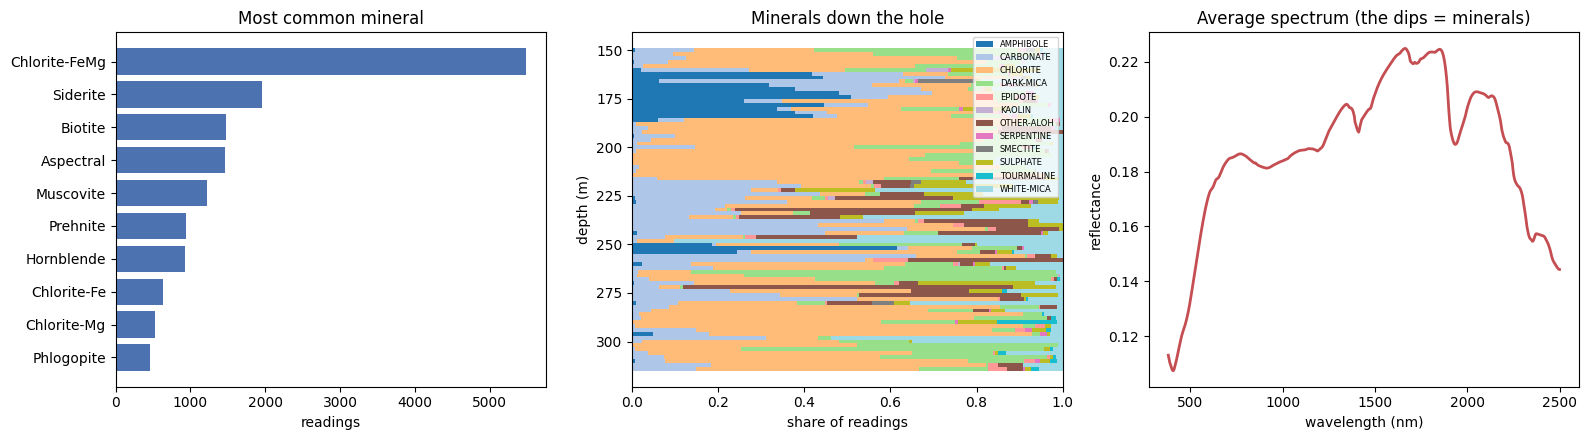

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# What minerals are in this hole?
top = data["mineral_1"].value_counts().head(10)
if len(top):
    axes[0].barh(top.index[::-1].astype(str), top.values[::-1], color="#4C72B0")
axes[0].set_title("Most common mineral")
axes[0].set_xlabel("readings")

# Where are they, down the hole?
groups = data.dropna(subset=["group_1"])
groups = groups[~groups["group_1"].isin(["INVALID", "NOTAROK"])]
if len(groups):
    binned = pd.crosstab((groups["depth_m"] // 2) * 2, groups["group_1"], normalize="index")
    left = np.zeros(len(binned))
    for colour, name in zip(plt.cm.tab20(np.linspace(0, 1, binned.shape[1])), binned.columns):
        axes[1].barh(binned.index, binned[name], left=left, height=2, label=name, color=colour)
        left += binned[name].values
    axes[1].invert_yaxis()
    axes[1].legend(fontsize=6, loc="upper right")
axes[1].set_ylabel("depth (m)")
axes[1].set_xlabel("share of readings")
axes[1].set_title("Minerals down the hole")
axes[1].grid(False)

# What does a spectrum look like?
axes[2].plot(nir.wavelength, nir.spectra.mean(axis=0), color="#C44E52", lw=2)
axes[2].set_xlabel("wavelength (nm)")
axes[2].set_ylabel("reflectance")
axes[2].set_title("Average spectrum (the dips = minerals)")

plt.tight_layout()
plt.show()

## Things you can now say in the meeting

Run the cells above on this hole and you can state, with numbers behind you:

- One hole is ~26,000 readings, one every few millimetres, over ~170 m of core.
- Each reading has 531 near-infrared + 341 thermal-infrared measurements, plus 151
  pre-computed columns.
- Only about **60%** of readings have a mineral identified — the rest are masked out.
- The mineral names are **software guesses from a reference library**, never verified
  against the rock.
- `INVALID` and `Aspectral` show up among the top "minerals" — they mean "couldn't tell".

### Worth asking them

1. How much do you trust `Min1`? Where does it usually get things wrong?
2. `sTSAS` vs `uTSAS` — the system and user libraries disagree. Which should we use?
3. Is there logged geology (rock type by depth) for these holes, so we can check our results?
4. What makes a depth interval *interesting* to you, as opposed to just statistically unusual?

### To look at a different hole

Change `SOURCE` at the top to another zip and run again. Everything else adapts.